In [1]:
!pip install pyDOE

  Preparing metadata (setup.py) ... done
  Created wheel for pyDOE: filename=pyDOE-0.3.8-py3-none-any.whl size=18168 sha256=e40d2de55a98e39c63b0aa6a27a676b720ca03971fec418966b7acd394b669a2
  Stored in directory: /root/.cache/pip/wheels/ce/b6/d7/c6b64746dba6433c593e471e0ac3acf4f36040456d1d160d17
Successfully built pyDOE


In [2]:
import jax
import jax.numpy as jnp
from flax import linen as nn
import optax
import copy
from typing import Callable

from functools import partial

import tensorflow as tf
from pyDOE import lhs
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import odeint
from scipy.special import erf

from jax import config
config.update("jax_enable_x64", True)

In [3]:
# Boundaries of the computational domain
t0, tfinal = 0.0, 0.25

In [4]:
# Parameters of the harmonic osciallator
k = 1.0
m = 1.0

In [5]:
# Define the normalization layer
class Normalize(nn.Module):
  xmin: float
  xmax: float

  @nn.compact
  def __call__(self, x):
    return 2.0*(x-self.xmin)/(self.xmax - self.xmin) - 1.0

In [6]:
class CombineBranches(nn.Module):
  @nn.compact
  def __call__(self, inp1, inp2):
    mult = jnp.sum(inp1*inp2, axis=1)
    # For consistency, we add the batch dimension back here
    out = jnp.reshape(mult, (-1,1))
    return out

In [7]:
class MLP(nn.Module):

  layers: int
  units: int

  @nn.compact
  def __call__(self, inp):
    b = inp
    for i in range(self.layers-1):
      b = nn.Dense(self.units)(b)
      b = nn.tanh(b)
    out = nn.Dense(2*self.units)(b)
    return out

In [8]:
class HardConstraint(nn.Module):
  t0: float
  tfinal: float
  u0: float

  @nn.compact
  def __call__(self, inputs):
    t, nn = inputs
    return self.u0 + (t-self.t0)/(self.tfinal-self.t0)*nn

In [9]:
class DeepONet(nn.Module):

  t0: float
  tfinal: float
  layers: int
  units: int

  @nn.compact
  def __call__(self, t, u):

    # # Add the batch dimension
    if u.ndim == 1:
      u = jnp.reshape(u, (1,-1))

    q0 = u[:,:1]
    p0 = u[:,1:]

    # Add the batch dimension
    t = jnp.reshape(t, (-1,1))

    b = Normalize(self.t0, self.tfinal)(t)

    trunk_net = MLP(self.layers, self.units)(b)
    branch_net = MLP(self.layers, self.units)(u)

    # Split into trunk/branch for q and p
    trunk_q = trunk_net[:,:self.units]
    trunk_p = trunk_net[:,self.units:]

    branch_q = branch_net[:,:self.units]
    branch_p = branch_net[:,self.units:]

    q = CombineBranches()(trunk_q, branch_q)
    p = CombineBranches()(trunk_p, branch_p)

    q = HardConstraint(self.t0, self.tfinal, q0)([t, q])
    p = HardConstraint(self.t0, self.tfinal, p0)([t, p])

    # Remove the batch dimension
    q = jnp.reshape(q, (-1,))
    p = jnp.reshape(p, (-1,))

    return q, p

In [10]:
# Create the model
deeponet = DeepONet(t0, tfinal, layers=4, units=40)

# Initialize the model parameters
params = deeponet.init(jax.random.PRNGKey(0), jnp.ones((10,)), jnp.ones((10,2)))

In [11]:
# Define the collocation points over the domain [t_0, t_1]
def defineCollocationPoints(t_bdry, N=100):

    # Sample points where to evaluate the PDE
  ode_points = t_bdry[0] + (t_bdry[1] - t_bdry[0])*lhs(1, N)
  zsensors = np.random.uniform(-1.0, 1.0, size=(N, 2))

  return (ode_points, zsensors)

In [12]:
# Define the collocation points
(de_points, zsensors) = defineCollocationPoints([t0, tfinal], 2000)

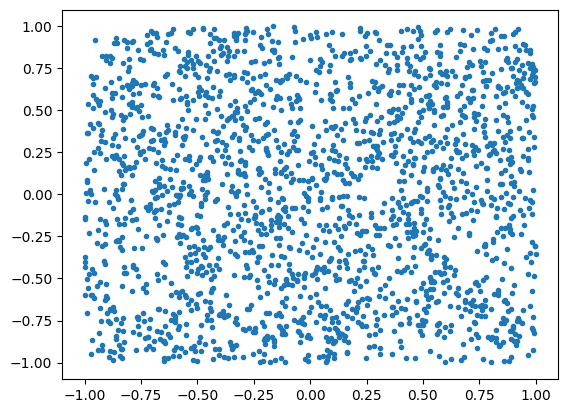

In [13]:
plt.plot(zsensors[:,0], zsensors[:,1],'.')

In [14]:
# Helper functions
@jax.jit
def q_model(t, z, params):
  return deeponet.apply(params, t, z)[0][0]

@jax.jit
def p_model(t, z, params):
  return deeponet.apply(params, t, z)[1][0]

@jax.jit
def q_t(t, z, params):
  return jax.vmap(jax.grad(q_model, 0), [0, 0, None])(t, z, params)

@jax.jit
def p_t(t, z, params):
  return jax.vmap(jax.grad(p_model, 0), [0, 0, None])(t, z, params)

@jax.jit
def loss(params, t, z):
  eqn1 = q_t(t, z, params) - jax.vmap(p_model, [0,0,None])(t, z, params)/m
  eqn2 = p_t(t, z, params) + jax.vmap(q_model, [0,0,None])(t, z, params)*k
  return jnp.mean(eqn1**2 + eqn2**2)

@jax.jit
def train_step(params, pdes, z):
  t = pdes[:,0]
  return jax.value_and_grad(loss)(params, t, z)

@partial(jax.jit, static_argnums=(3,))
def optimize(grads, opt_state, params, optimizer_update):
  updates, opt_state = optimizer_update(grads, opt_state, params)
  params = optax.apply_updates(params, updates)
  return params, opt_state

In [15]:
def train_network(params, des, zsensor, epochs=100):

  # Number of ICs and total number of DE collocation points
  N = de_points.shape[0]

  nr_batches = 10
  batch_size = len(des)//nr_batches

  lr = 1e-3
  optimizer = optax.adam(lr)
  opt_state = optimizer.init(params)

  ds_z = tf.data.Dataset.from_tensor_slices(zsensors)
  ds_de = tf.data.Dataset.from_tensor_slices(des)

  ds = tf.data.Dataset.zip((ds_de, ds_z))
  ds = ds.shuffle(N).batch(batch_size)

  epoch_loss = np.zeros(epochs)

  for i in range(epochs):

    for (des_batch, z_batch) in ds:

      loss, grads = train_step(params, des_batch.numpy(), z_batch.numpy())
      params, opt_state = optimize(grads, opt_state, params, optimizer.update)

      epoch_loss[i] += loss

    epoch_loss[i] /= batch_size

    if i % 100 == 0:
      print(f'Loss in epoch {i}: {epoch_loss[i]}')

  return params, epoch_loss

In [16]:
epochs = 2000
params, loss = train_network(params, de_points, zsensors, epochs)

Loss in epoch 0: 0.29948689959604574
Loss in epoch 100: 0.0002392955071320628
Loss in epoch 200: 3.343476333583252e-05
Loss in epoch 300: 5.099142541826428e-05
Loss in epoch 400: 1.617997692658807e-05
Loss in epoch 500: 5.371306368704373e-05
Loss in epoch 600: 4.4099501007424625e-06
Loss in epoch 700: 5.008279582865362e-06
Loss in epoch 800: 5.812724343951806e-06
Loss in epoch 900: 1.0141919768915787e-05
Loss in epoch 1000: 5.198577673228506e-06
Loss in epoch 1100: 5.607688444463529e-06
Loss in epoch 1200: 1.2940095755612662e-06
Loss in epoch 1300: 2.972375917950944e-06
Loss in epoch 1400: 5.4535850414977505e-06
Loss in epoch 1500: 4.3137182801388364e-06
Loss in epoch 1600: 1.890358596476481e-06
Loss in epoch 1700: 3.6449728763718395e-06
Loss in epoch 1800: 8.897838144930836e-06
Loss in epoch 1900: 1.5091238127837626e-06


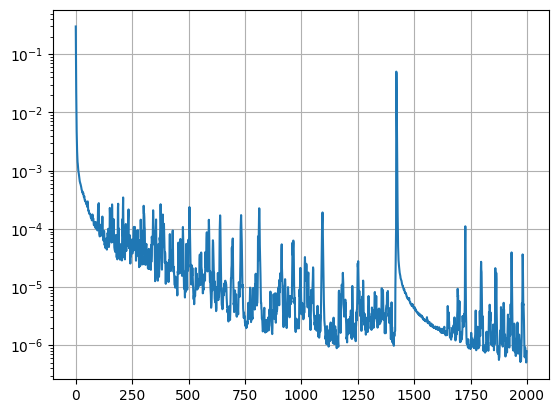

In [17]:
plt.semilogy(loss)
plt.grid()

In [18]:
# Grid where to evaluate the model
n = 200
t = np.linspace(t0, tfinal, n)

# Sample a new IC
init_data = np.random.uniform(-1.0, 1.0, size=(2,))
z = np.repeat(np.expand_dims(init_data, axis=0), len(t), axis=0)

# Model prediction
q = jax.vmap(q_model, [0, 0, None])(t, z, params)
p = jax.vmap(p_model, [0, 0, None])(t, z, params)

In [19]:
def ho(y, t):
  q, p = y
  dydt = [p/m, -k*q]
  return dydt

sol_rk = odeint(ho, init_data, t)

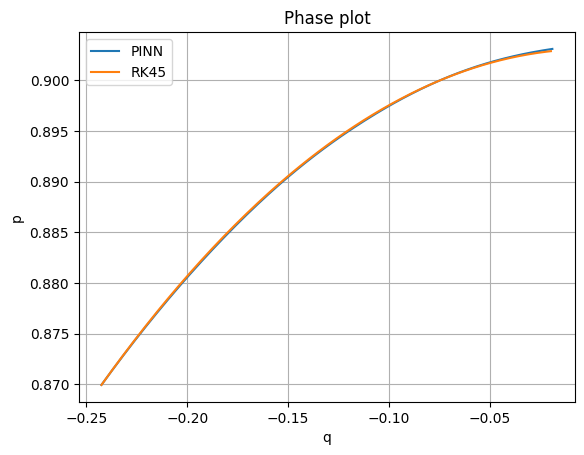

In [20]:
plt.plot(q, p)
plt.plot(sol_rk[:,0], sol_rk[:,1])
plt.legend(['PINN', 'RK45'])
plt.grid()
plt.xlabel('q')
plt.ylabel('p')
plt.title('Phase plot')
plt.savefig('PhasePlot1D.png')

Text(0.5, 1.0, 'Hamiltonian l2-error: 0.00115')

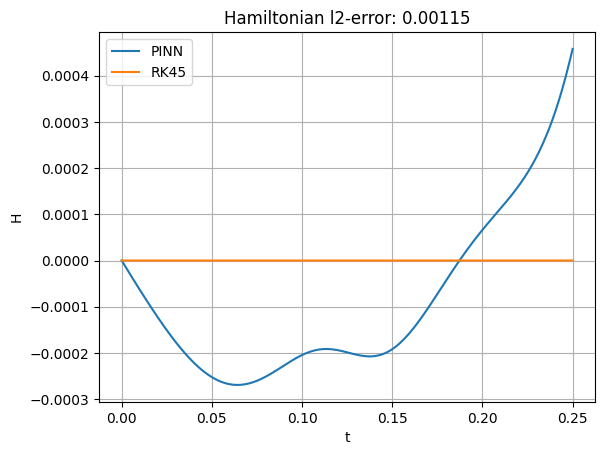

In [21]:
Hs = p**2/(2*m) + k*q**2/2
H_rk = sol_rk[:,1]**2/(2*m) + k*sol_rk[:,0]**2/2

plt.plot(t, (Hs-Hs[0])/Hs[0])
plt.plot(t, (H_rk-H_rk[0])/H_rk[0])
plt.legend(['PINN', 'RK45'])
plt.grid()
plt.xlabel('t')
plt.ylabel('H')
plt.title(f'Hamiltonian l2-error: {np.linalg.norm((Hs-Hs[0])):2.5f}')

In [22]:
H = lambda q, p, q0, p0: p**2/(2*m) + k*q**2/2 - (p0**2/(2*m) + k*q0**2/2)
dlambda = lambda q, p, q0, p0, l: -1.0/((k*q)**2+(p/m)**2)*H(q+k*q*l, p+p/m*l, q0, p0)

In [23]:
class ProjectionLayer(nn.Module):

  iterations: int = 50

  @nn.compact
  def __call__(self, inputs):
    q, p, q0, p0 = inputs
    l = 0
    for i in range(self.iterations):
      l += dlambda(q, p, q0, p0, l)
    qc = q + l*q*k
    pc = p + l*p/m
    return qc, pc

In [24]:
class cDeepONet(nn.Module):

  t0: float
  tfinal: float
  layers: int
  units: int

  @nn.compact
  def __call__(self, t, u):

    # # Add the batch dimension
    if u.ndim == 1:
      u = jnp.reshape(u, (1,-1))

    q0 = u[:,:1]
    p0 = u[:,1:]

    # Add the batch dimension
    t = jnp.reshape(t, (-1,1))

    b = Normalize(self.t0, self.tfinal)(t)

    trunk_net = MLP(self.layers, self.units)(b)
    branch_net = MLP(self.layers, self.units)(u)

    trunk_q = trunk_net[:,:self.units]
    trunk_p = trunk_net[:,self.units:]

    branch_q = branch_net[:,:self.units]
    branch_p = branch_net[:,self.units:]

    outq = CombineBranches()(trunk_q, branch_q)
    outp = CombineBranches()(trunk_p, branch_p)

    outq = HardConstraint(self.t0, self.tfinal, q0)([t, outq])
    outp = HardConstraint(self.t0, self.tfinal, p0)([t, outp])

    # CL projection layer
    outq, outp = ProjectionLayer()([outq, outp, q0, p0])

    # Remove the batch dimension
    outq = jnp.reshape(outq, (-1,))
    outp = jnp.reshape(outp, (-1,))

    return outq, outp

In [25]:
# Create the model
cdeeponet = cDeepONet(t0, tfinal, layers=4, units=40)

# Initialize the model parameters
cparams = cdeeponet.init(jax.random.PRNGKey(0), jnp.ones((10,)), jnp.ones((10,2)))

# Copy the parameters from the trained non-conservative model
cparams = copy.deepcopy(params)

In [26]:
# Helper functions
@jax.jit
def qc_model(t, z, params):
  return cdeeponet.apply(params, t, z)[0][0]

@jax.jit
def pc_model(t, z, params):
  return cdeeponet.apply(params, t, z)[1][0]

@jax.jit
def qc_t(t, z, params):
  return jax.vmap(jax.grad(qc_model, 0), [0, 0, None])(t, z, params)

@jax.jit
def pc_t(t, z, params):
  return jax.vmap(jax.grad(pc_model, 0), [0, 0, None])(t, z, params)

@jax.jit
def loss(params, t, z):
  eqn1 = qc_t(t, z, params) - jax.vmap(pc_model, [0,0,None])(t, z, params)/m
  eqn2 = pc_t(t, z, params) + jax.vmap(qc_model, [0,0,None])(t, z, params)*k
  return jnp.mean(eqn1**2 + eqn2**2)

@jax.jit
def train_step(params, pdes, z):
  t = pdes[:,0]
  return jax.value_and_grad(loss)(params, t, z)

@partial(jax.jit, static_argnums=(3,))
def optimize(grads, opt_state, params, optimizer_update):
  updates, opt_state = optimizer_update(grads, opt_state, params)
  params = optax.apply_updates(params, updates)
  return params, opt_state

In [27]:
def train_network(params, des, zsensor, epochs=100):

  # Number of ICs and total number of DE collocation points
  N = de_points.shape[0]

  nr_batches = 10
  batch_size = len(des)//nr_batches

  lr = 1e-3
  optimizer = optax.adam(lr)
  opt_state = optimizer.init(params)

  ds_z = tf.data.Dataset.from_tensor_slices(zsensors)
  ds_de = tf.data.Dataset.from_tensor_slices(des)

  ds = tf.data.Dataset.zip((ds_de, ds_z))
  ds = ds.shuffle(N).batch(batch_size)

  epoch_loss = np.ones(epochs)

  for i in range(epochs):

    for (des_batch, z_batch) in ds:

      loss, grads = train_step(params, des_batch.numpy(), z_batch.numpy())
      params, opt_state = optimize(grads, opt_state, params, optimizer.update)

      epoch_loss[i] += loss

    epoch_loss[i] /= batch_size

    if i % 100 == 0:
      print(f'Loss in epoch {i}: {epoch_loss[i]}')

  return params, epoch_loss

In [28]:
# cparams, loss = train_network(cparams, de_points, zsensors, epochs)

In [29]:
# Grid where to evaluate the model
n = 200
t = np.linspace(t0, tfinal, n)

# Model prediction
qc = jax.vmap(qc_model, [0, 0, None])(t, z, cparams)
pc = jax.vmap(pc_model, [0, 0, None])(t, z, cparams)

Text(0.5, 1.0, 'Phase plot')

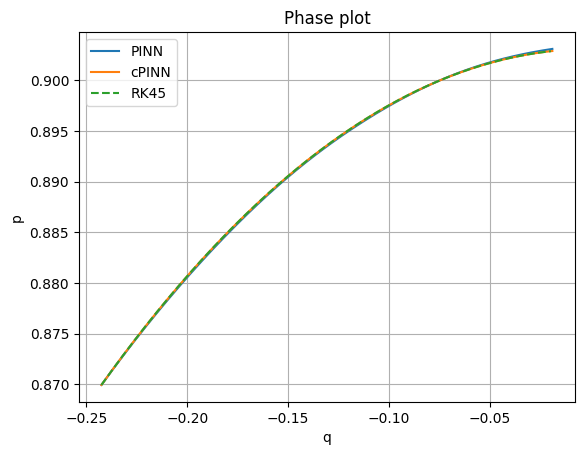

In [30]:
plt.plot(q, p)
plt.plot(qc, pc)
plt.plot(sol_rk[:,0], sol_rk[:,1],'--')
plt.legend(['PINN', 'cPINN', 'RK45'])
plt.grid()
plt.xlabel('q')
plt.ylabel('p')
plt.title('Phase plot')

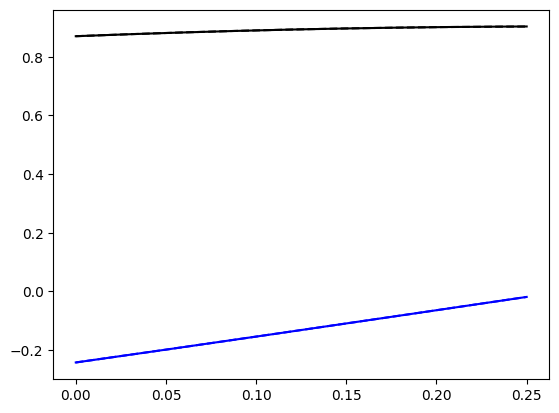

In [31]:
plt.plot(t, q,'b')
plt.plot(t, qc,'b--')

plt.plot(t, p, 'k')
plt.plot(t, pc, 'k--')

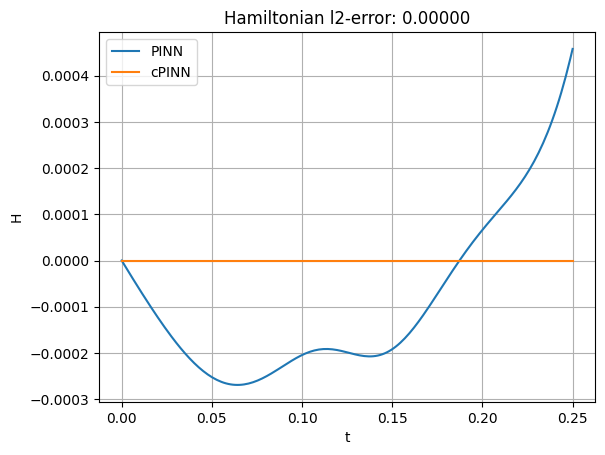

In [32]:
Hc = pc**2/(2*m) + k*qc**2/2
H_rk = sol_rk[:,1]**2/(2*m) + k*sol_rk[:,0]**2/2

plt.plot(t, (Hs-Hs[0])/Hs[0])
plt.plot(t, (Hc-Hc[0])/Hc[0])
plt.legend(['PINN', 'cPINN'])
plt.grid()
plt.xlabel('t')
plt.ylabel('H')
plt.title(f'Hamiltonian l2-error: {np.linalg.norm((Hc-Hc[0])):2.5f}')
plt.savefig('Hamiltonian1D.png')

### Time stepping

In [33]:
steps = 1000
tfinalsteps = tfinal*steps
tt = np.linspace(0, tfinalsteps, (n-1)*steps)

In [34]:
# Non-conservative method
zinit = init_data

zall = []

for i in range(steps):
  zinit = np.repeat(np.expand_dims(zinit, axis=0), len(t), axis=0)

  q = jax.vmap(q_model, [0, 0, None])(t, zinit, params)
  p = jax.vmap(p_model, [0, 0, None])(t, zinit, params)

  zinit = np.array([q[-1], p[-1]])
  zall.append(np.column_stack([q[:-1], p[:-1]]))

zall = np.concatenate(zall, axis=0)

In [35]:
# Conservative method
zinit = init_data

zcall = []

for i in range(steps):
  zinit = np.repeat(np.expand_dims(zinit, axis=0), len(t), axis=0)

  q = jax.vmap(qc_model, [0, 0, None])(t, zinit, params)
  p = jax.vmap(pc_model, [0, 0, None])(t, zinit, params)

  zinit = np.array([q[-1], p[-1]])
  zcall.append(np.column_stack([q[:-1], p[:-1]]))

zcall = np.concatenate(zcall, axis=0)

In [36]:
# RK reference solution
sol_rk_all = odeint(ho, init_data, tt)

Text(0.5, 0, 'q')

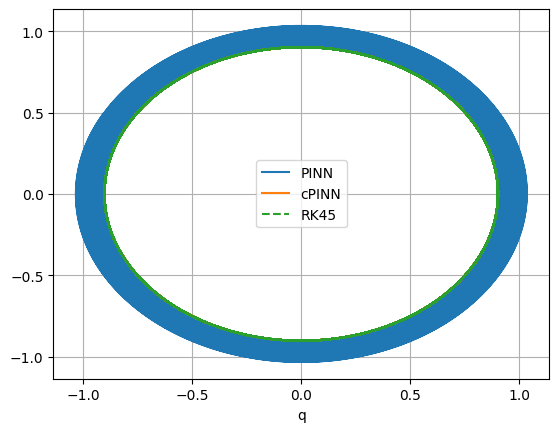

In [37]:
plt.plot(zall[:,0], zall[:,1])
plt.plot(zcall[:,0], zcall[:,1])
plt.plot(sol_rk_all[:,0], sol_rk_all[:,1],'--')
plt.legend(['PINN', 'cPINN', 'RK45'])
plt.grid()
plt.xlabel('q')

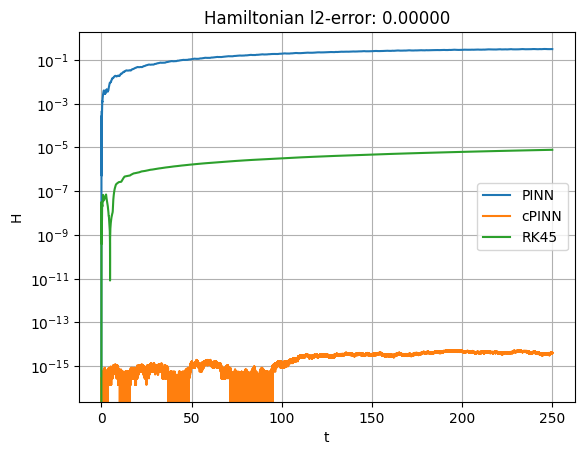

In [38]:
Hs = zall[:,1]**2/(2*m) + k*zall[:,0]**2/2
Hc = zcall[:,1]**2/(2*m) + k*zcall[:,0]**2/2
H_rk = sol_rk_all[:,1]**2/(2*m) + k*sol_rk_all[:,0]**2/2

plt.semilogy(tt, np.abs(Hs-Hs[0])/Hs[0])
plt.semilogy(tt, np.abs(Hc-Hc[0])/Hc[0])
plt.semilogy(tt, np.abs(H_rk-H_rk[0])/H_rk[0])
plt.legend(['PINN', 'cPINN', 'RK45'])
plt.grid()
plt.xlabel('t')
plt.ylabel('H')
plt.title(f'Hamiltonian l2-error: {np.linalg.norm((Hc-Hc[0])):2.5f}')
plt.savefig('Hamiltonian1D.png')